In [1]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf

fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()

In [3]:
fashion_mnist

((array([[[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         ...,
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0

In [8]:
(x_train_f, y_train_f),(x_test, y_test) = fashion_mnist

In [9]:
x_train, y_train = x_train_f[:-5000],y_train_f[:-5000]
x_valid,y_valid = x_train_f[-5000:],y_train_f[-5000:]

In [10]:
print("shape of x_train",x_train.shape)
print("shape of y_train",y_train.shape)
print("shape of x_valid",x_valid.shape)
print("shape of y_valid",y_valid.shape)

shape of x_train (55000, 28, 28)
shape of y_train (55000,)
shape of x_valid (5000, 28, 28)
shape of y_valid (5000,)


In [11]:
print("Data Type",x_train.dtype)

Data Type uint8


In [12]:
x_train, x_valid, x_test = x_train/255.0, x_valid/255.0, x_test/255.0

In [13]:
y_train[0]

np.uint8(9)

In [14]:
y_train[5]

np.uint8(2)

In [15]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
"Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [16]:
class_names[y_train[1]]

'T-shirt/top'

In [17]:
tf.random.set_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28,28]),
    tf.keras.layers.Dense(300,activation="relu"),
    tf.keras.layers.Dense(100,activation="relu"),
    tf.keras.layers.Dense(10,activation="softmax")
])

c:\Users\kumar\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.layers

[<Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dense name=dense_1, built=True>,
 <Dense name=dense_2, built=True>]

In [20]:
model.layers[1].name

'dense'

In [21]:
model.layers[2].get_weights()

[array([[ 0.00864028,  0.10025144,  0.00151114, ...,  0.01343203,
          0.07559372, -0.01477346],
        [ 0.05991658, -0.09849517,  0.09708074, ...,  0.00515261,
          0.06689736,  0.00983541],
        [-0.07790329, -0.11680626, -0.0520591 , ..., -0.10401447,
          0.07790325, -0.02411337],
        ...,
        [-0.03607392,  0.10628875, -0.10457932, ..., -0.08542183,
          0.02145044, -0.00600803],
        [-0.08955842,  0.10789237,  0.02344265, ...,  0.10948896,
         -0.11702947,  0.05780257],
        [ 0.0006003 , -0.00026482,  0.0170851 , ...,  0.11632624,
         -0.03787907,  0.08899774]], shape=(300, 100), dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 

In [22]:
w,b = model.layers[2].get_weights()
b.shape
w.shape

(300, 100)

In [23]:
model.compile(optimizer="sgd",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [25]:
modelTrain = model.fit(x_train,y_train,epochs=40,validation_data=(x_valid,y_valid))

Epoch 1/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7586 - loss: 0.7306 - val_accuracy: 0.8204 - val_loss: 0.5224
Epoch 2/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8302 - loss: 0.4922 - val_accuracy: 0.8440 - val_loss: 0.4622
Epoch 3/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8458 - loss: 0.4462 - val_accuracy: 0.8526 - val_loss: 0.4366
Epoch 4/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8547 - loss: 0.4186 - val_accuracy: 0.8576 - val_loss: 0.4192
Epoch 5/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8615 - loss: 0.3983 - val_accuracy: 0.8614 - val_loss: 0.4058
Epoch 6/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8668 - loss: 0.3822 - val_accuracy: 0.8664 - val_loss: 0.3959
Epoch 7/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8715 - loss: 0.3685 - val_accuracy: 0.8682 - val_loss: 0.3899
Epoch 8/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8751 - loss: 0.3568 - 

In [26]:
modelTrain.epoch

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 39]

In [27]:
modelTrain.params

{'verbose': 'auto', 'epochs': 40, 'steps': 1719}

In [28]:
modelTrain.history

{'accuracy': [0.7586363554000854,
  0.8302000164985657,
  0.8457818031311035,
  0.8546727299690247,
  0.8614727258682251,
  0.8667818307876587,
  0.8714545369148254,
  0.875072717666626,
  0.8789818286895752,
  0.8820182085037231,
  0.8844363689422607,
  0.8867818117141724,
  0.8892909288406372,
  0.891945481300354,
  0.8944181799888611,
  0.8967272639274597,
  0.8990181684494019,
  0.9007454514503479,
  0.9025636315345764,
  0.9044363498687744,
  0.906181812286377,
  0.9081090688705444,
  0.9096909165382385,
  0.9113273024559021,
  0.9127636551856995,
  0.914581835269928,
  0.9159272909164429,
  0.9172000288963318,
  0.9189454317092896,
  0.920127272605896,
  0.9216363430023193,
  0.9233272671699524,
  0.9243636131286621,
  0.9262363910675049,
  0.9275272488594055,
  0.9289818406105042,
  0.9299091100692749,
  0.9315817952156067,
  0.9323272705078125,
  0.9339636564254761],
 'loss': [0.7306329011917114,
  0.49218571186065674,
  0.4462019205093384,
  0.4186290204524994,
  0.39831441640

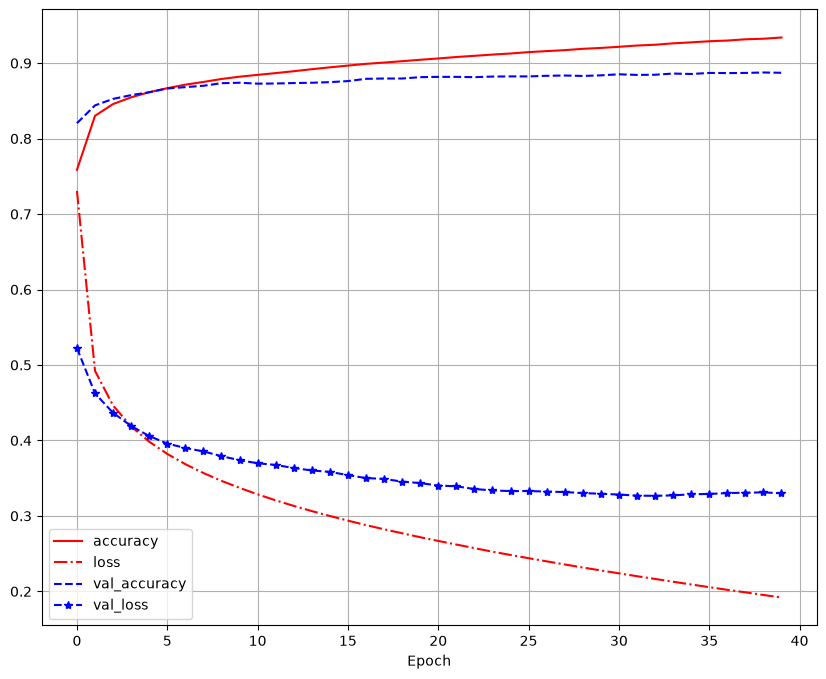

In [29]:
import matplotlib.pyplot as plt
import pandas as pd

pd.DataFrame(modelTrain.history).plot(figsize=(10,8),grid=True,xlabel="Epoch",
                                      style = ['r-','r-.','b--','b--*'])
plt.show()

In [30]:
model.evaluate(x_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8807 - loss: 0.3475


[0.34752723574638367, 0.8806999921798706]

In [31]:
x_new = x_test[:4]

In [32]:
y_probab = model.predict(x_new).round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step


In [33]:
import numpy as np

y_pred = y_probab.argmax(axis = -1)
y_pred

array([9, 2, 1, 1])

In [34]:
np.array(class_names)[y_pred]

array(['Ankle boot', 'Pullover', 'Trouser', 'Trouser'], dtype='<U11')